# Predicting mean temperature in London

![tower_bridge](tower_bridge.jpeg)

This notebook compares regression models for predicting London's daily mean temperature from other weather measurements, and uses MLflow to keep track of the experiments.

`london_weather.csv` holds daily observations from 1979 to 2020:

| Column | Description |
|---|---|
| `date` | Date of measurement (YYYYMMDD) |
| `cloud_cover` | Cloud cover in oktas |
| `sunshine` | Hours of sunshine |
| `global_radiation` | Irradiance in W/m² |
| `max_temp`, `mean_temp`, `min_temp` | Temperatures in °C |
| `precipitation` | Precipitation in mm |
| `pressure` | Pressure in Pa |
| `snow_depth` | Snow depth in cm |

In [1]:
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

weather = pd.read_csv("london_weather.csv")
weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 15341 entries, 0 to 15340
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              15341 non-null  int64  
 1   cloud_cover       15322 non-null  float64
 2   sunshine          15341 non-null  float64
 3   global_radiation  15322 non-null  float64
 4   max_temp          15335 non-null  float64
 5   mean_temp         15305 non-null  float64
 6   min_temp          15339 non-null  float64
 7   precipitation     15335 non-null  float64
 8   pressure          15337 non-null  float64
 9   snow_depth        13900 non-null  float64
dtypes: float64(9), int64(1)
memory usage: 1.2 MB


## 1. Exploratory analysis

In [2]:
weather["date"] = pd.to_datetime(weather["date"], format="%Y%m%d")
weather["year"] = weather["date"].dt.year
weather["month"] = weather["date"].dt.month

weather.isna().sum()

date                   0
cloud_cover           19
sunshine               0
global_radiation      19
max_temp               6
mean_temp             36
min_temp               2
precipitation          6
pressure               4
snow_depth          1441
year                   0
month                  0
dtype: int64

Annual mean temperature has risen over the four decades:

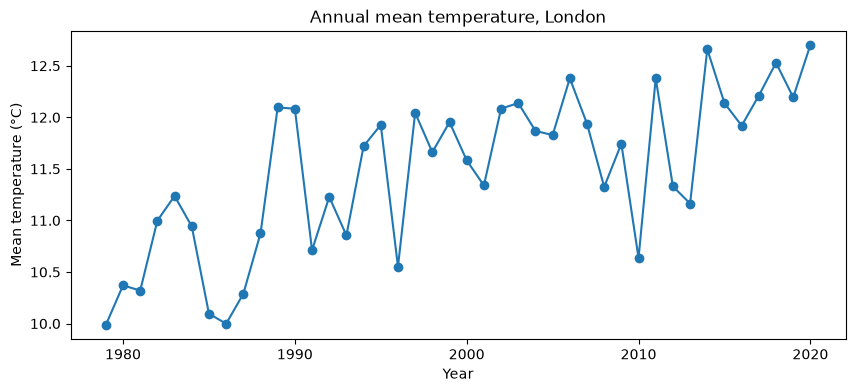

1979-1988 average: 10.51 °C
2011-2020 average: 12.12 °C


In [3]:
annual = weather.groupby("year")["mean_temp"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(annual.index, annual.values, marker="o")
ax.set_xlabel("Year")
ax.set_ylabel("Mean temperature (°C)")
ax.set_title("Annual mean temperature, London")
plt.show()

print(f"1979-1988 average: {annual.loc[1979:1988].mean():.2f} °C")
print(f"2011-2020 average: {annual.loc[2011:2020].mean():.2f} °C")

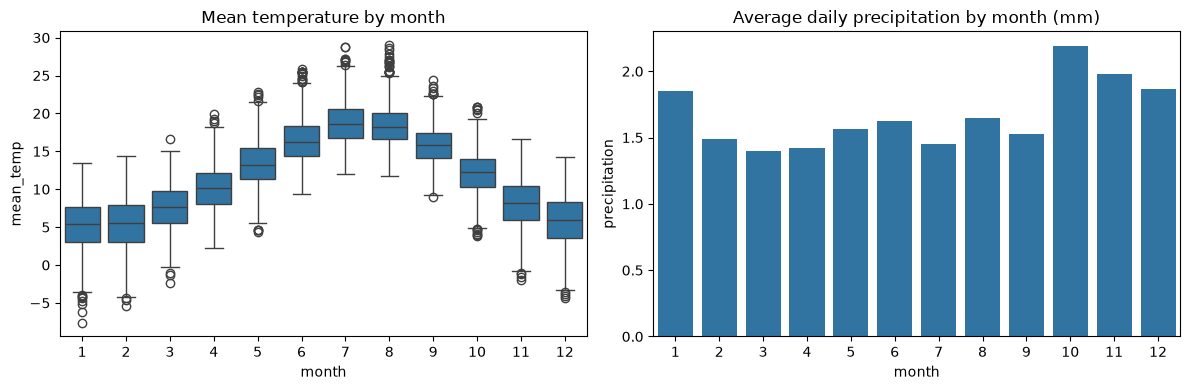

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="month", y="mean_temp", data=weather, ax=axes[0])
axes[0].set_title("Mean temperature by month")
sns.barplot(x="month", y="precipitation", data=weather, errorbar=None, ax=axes[1])
axes[1].set_title("Average daily precipitation by month (mm)")
plt.tight_layout()
plt.show()

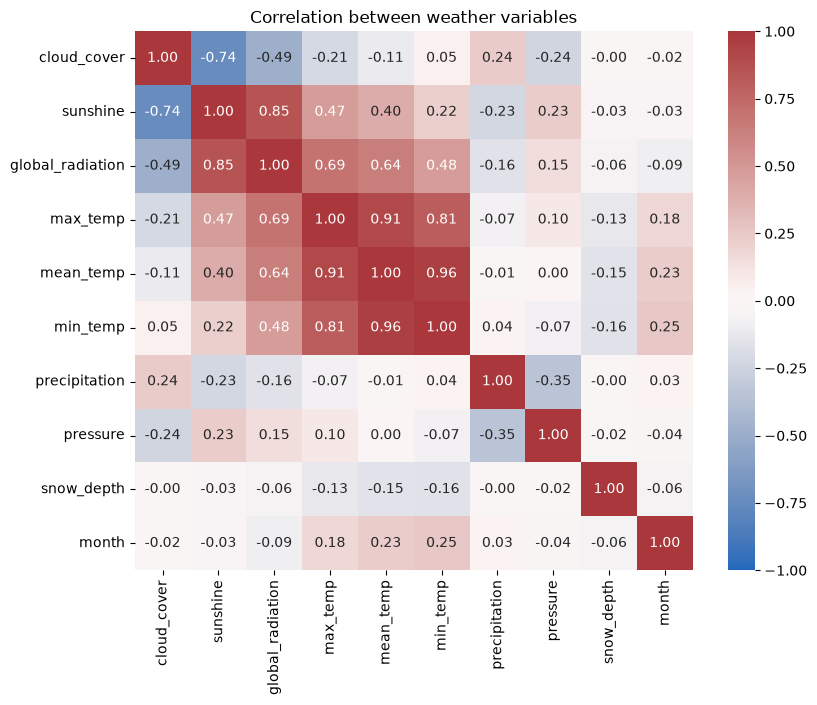

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(weather.drop(columns=["date", "year"]).corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between weather variables")
plt.show()

## 2. Features and target

`max_temp` and `min_temp` are left out. They are almost perfectly correlated with the target and would make the task trivial. Rows without a `mean_temp` are dropped; gaps in the features are imputed inside the model pipeline.

Month is a cycle (December is next to January), so it is encoded as a sine/cosine pair rather than as the numbers 1-12.

In [6]:
weather = weather.dropna(subset=["mean_temp"]).copy()
weather["month_sin"] = np.sin(2 * np.pi * weather["month"] / 12)
weather["month_cos"] = np.cos(2 * np.pi * weather["month"] / 12)

features = ["month_sin", "month_cos", "cloud_cover", "sunshine", "precipitation", "pressure", "global_radiation"]
target = "mean_temp"

X_train, X_test, y_train, y_test = train_test_split(
    weather[features], weather[target], test_size=0.33, random_state=1
)
print(X_train.shape, X_test.shape)

(10254, 7) (5051, 7)


## 3. Experiments tracked with MLflow

Each run fits one model and logs its parameters and test RMSE. Linear regression is fitted once; the decision tree and random forest are tried at five depths. `set_experiment` creates the experiment if needed and reuses it otherwise, so the notebook can be re-run safely.

In [7]:
def make_model(estimator):
    """Impute and scale the features, then fit the given estimator."""
    return make_pipeline(SimpleImputer(strategy="mean"), StandardScaler(), estimator)


def rmse(model, X, y):
    return float(np.sqrt(mean_squared_error(y, model.predict(X))))


mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("weather_prediction")

runs = [("linear_regression", LinearRegression(), None)]
for depth in [1, 2, 5, 10, 20]:
    runs.append(("decision_tree", DecisionTreeRegressor(max_depth=depth, random_state=42), depth))
    runs.append(("random_forest", RandomForestRegressor(max_depth=depth, n_estimators=100, random_state=42, n_jobs=-1), depth))

results = []
for name, estimator, depth in runs:
    with mlflow.start_run(run_name=name if depth is None else f"{name}_depth_{depth}"):
        model = make_model(estimator).fit(X_train, y_train)
        scores = {"rmse_train": rmse(model, X_train, y_train), "rmse_test": rmse(model, X_test, y_test)}
        mlflow.log_param("model", name)
        mlflow.log_param("max_depth", depth)
        mlflow.log_metrics(scores)
        results.append({"model": name, "max_depth": depth, **scores})

results = pd.DataFrame(results)
results.sort_values("rmse_test").round(3)

,model,max_depth,rmse_train,rmse_test
8,random_forest,10.0,2.307,2.804
10,random_forest,20.0,1.160,2.877
6,random_forest,5.0,2.816,2.898
5,decision_tree,5.0,2.875,2.961
0,linear_regression,NaN,2.947,2.996
7,decision_tree,10.0,2.426,3.083
4,random_forest,2.0,3.209,3.265
3,decision_tree,2.0,3.366,3.399
9,decision_tree,20.0,0.791,3.835
2,random_forest,1.0,4.539,4.565


The same results can be read back from the MLflow store:

In [8]:
logged = mlflow.search_runs(experiment_names=["weather_prediction"], order_by=["metrics.rmse_test ASC"])
logged[["tags.mlflow.runName", "params.max_depth", "metrics.rmse_train", "metrics.rmse_test"]].head(5).round(3)

,tags.mlflow.runName,params.max_depth,metrics.rmse_train,metrics.rmse_test
0,random_forest_depth_10,10,2.307,2.804
1,random_forest_depth_20,20,1.160,2.877
2,random_forest_depth_5,5,2.816,2.898
3,decision_tree_depth_5,5,2.875,2.961
4,linear_regression,None,2.947,2.996


## 4. Effect of tree depth

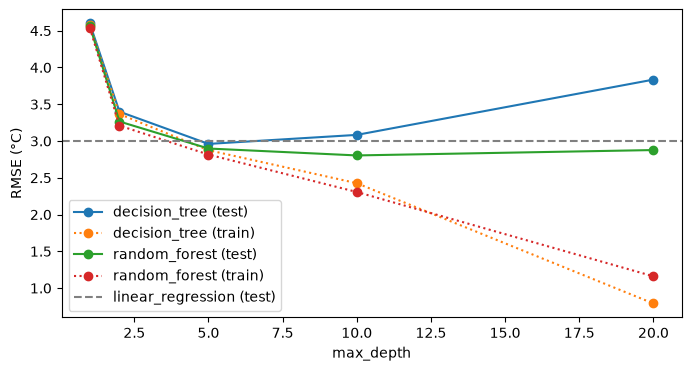

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, grp in results.dropna(subset=["max_depth"]).groupby("model"):
    ax.plot(grp["max_depth"], grp["rmse_test"], marker="o", label=f"{name} (test)")
    ax.plot(grp["max_depth"], grp["rmse_train"], marker="o", linestyle=":", label=f"{name} (train)")
ax.axhline(results.loc[results["model"] == "linear_regression", "rmse_test"].iloc[0],
           color="grey", linestyle="--", label="linear_regression (test)")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE (°C)")
ax.legend()
plt.show()

## Findings

- London has warmed: the annual mean temperature averaged 10.5 °C over 1979-1988 and 12.1 °C over 2011-2020.
- The best model is a random forest with `max_depth=10`, with a test RMSE of about 2.8 °C. Linear regression is not far behind at 3.0 °C, so most of the signal is captured by simple seasonal and radiation effects.
- A single decision tree overfits badly once it is allowed to grow: at depth 20 its training error drops to 0.8 °C while its test error rises to 3.8 °C. The random forest is much more robust to depth.

Limitations: the train/test split is random, so neighbouring days end up on both sides. For actual forecasting, a split by date and lagged features (for example yesterday's temperature) would be the right setup, and would likely do much better than 2.8 °C.